# Tensorflow Environment for Deep Learning

0. Tensorflow + GPU setup
1. Load the data
2. EDA
3. Input piepline `tf.data`
4. Fully connected ANN
5. Train and evaluate
6. Visualization - Tensorboard
7. Compare Tf-Keras / TFLearn
8. Experiment on Architecture

In [ ]:
# 0. library
import tensorflow as tf

print("Tensorflow version:", tf.__version__)
print("GPU is", "available" if tf.test.is_gpu_available() else "NOT AVAILABLE")



Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


Tensorflow version: 2.20.0
GPU is available


In [ ]:
# check for CUDA
cuda = tf.sysconfig.get_build_info()

print("CUDA version:", cuda["cuda_version"])
print("cuDNN version:", cuda["cudnn_version"])

CUDA version: 12.5.1
cuDNN version: 9


### 1. Load the Cats vs Dogs example

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("biaiscience/dogs-vs-cats")

print("Path to dataset files:", path)

100%|██████████| 817M/817M [00:10<00:00, 81.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/biaiscience/dogs-vs-cats/versions/1


In [ ]:
# copy the folder to content folder making it public

import shutil
shutil.copytree(path, "/content/dogs-vs-cats")



'/content/dogs-vs-cats'

In [ ]:
# go for making X_train, X_test, y_train, y_test
import os
import cv2
import numpy as np

train_data = "/content/dogs-vs-cats/train/train"
test_data = "/content/dogs-vs-cats/test/test"
IMG_SIZE = 128

X_train = []
y_train = []

for img_file in os.listdir(train_data):
    if img_file.endswith('.jpg'): # Ensure it's an image file
        label = 0 if 'cat' in img_file else 1 # 0 for cat, 1 for dog
        img_path = os.path.join(train_data, img_file)
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X_train.append(img)
        y_train.append(label)

X_test = []
y_test = []

for img_file in os.listdir(test_data):
    if img_file.endswith('.jpg'): # Ensure it's an image file
        # Test data filenames don't have labels directly, they are just IDs.
        # For now, we will just load the images. Labels for test data are usually separate.
        # If this is for prediction, we might not need y_test labels at this stage.
        # For demonstration, we'll create a placeholder y_test if needed, or just X_test.
        # Assuming test images need to be loaded for prediction without known labels.
        # If labels for test data are available separately, they should be loaded then.
        img_path = os.path.join(test_data, img_file)
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X_test.append(img)
        # For now, we won't append labels to y_test as they are not in filename for test set

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)


print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")


X_train shape: (25000, 128, 128, 3)
y_train shape: (25000,)
X_test shape: (12500, 128, 128, 3)


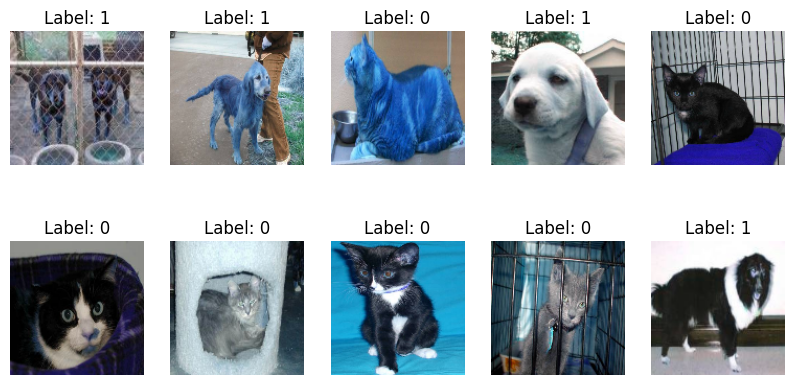

In [ ]:
# print 10 images with labels
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 5, figsize=(10, 5))
for i in range(10):
    ax[i // 5, i % 5].imshow(X_train[i])
    ax[i // 5, i % 5].set_title(f"Label: {y_train[i]}")
    ax[i // 5, i % 5].axis('off')
plt.show()

In [ ]:
type(X_train)

numpy.ndarray

In [ ]:
# distribution
unique, counts = np.unique(y_train, return_counts=True)
print(np.asarray((unique, counts)).T)

[[    0 12500]
 [    1 12500]]


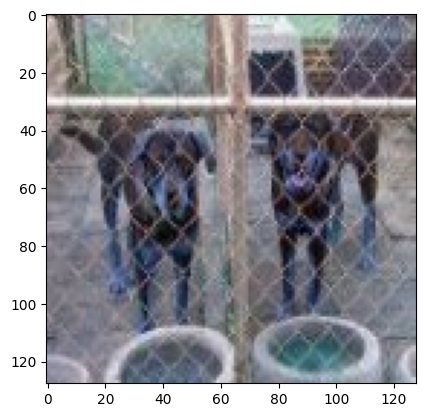

In [ ]:
# 1st image
img = X_train[0]
plt.imshow(img)
plt.show()

In [ ]:
# matrix shape
img.shape

(128, 128, 3)

In [ ]:
# matrix in numbers
print(img[:][:][:])

[[[114  92  87]
  [124 105 100]
  [ 63  46  43]
  ...
  [ 95  90  98]
  [102  97 102]
  [ 86  80  85]]

 [[197 175 170]
  [198 178 174]
  [172 155 152]
  ...
  [ 98  95 102]
  [ 91  86  91]
  [ 88  82  87]]

 [[204 182 177]
  [236 220 214]
  [199 183 178]
  ...
  [112 109 117]
  [104 100 105]
  [111 107 112]]

 ...

 [[131 131 149]
  [140 140 158]
  [145 145 163]
  ...
  [194 199 213]
  [165 169 181]
  [147 151 162]]

 [[141 141 159]
  [134 134 152]
  [133 133 151]
  ...
  [181 188 201]
  [199 203 215]
  [204 208 219]]

 [[134 134 152]
  [133 133 151]
  [133 133 151]
  ...
  [173 181 194]
  [189 196 208]
  [201 207 218]]]


#### Preprocess

In [ ]:
# flatten
X_train = X_train.reshape(-1, IMG_SIZE*IMG_SIZE*3)
X_test = X_test.reshape(-1, IMG_SIZE*IMG_SIZE*3)

# shape
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (25000, 49152)
X_test shape: (12500, 49152)


In [ ]:
# take first 1000 images for training
X_train_1000 = X_train[:1000]
y_train_1000 = y_train[:1000]
X_test_1000 = X_test[:1000]
y_test_1000 = y_test[:1000]
# shape
print(f"X_train shape: {X_train_1000.shape}")
print(f"y_train shape: {y_train_1000.shape}")

X_train shape: (1000, 49152)
y_train shape: (1000,)


#### Baseline model - ANN with 256->128->64 units

In [ ]:
import tensorflow as tf
model_1 = tf.keras.models.Sequential([
    tf.keras.layers.Dense(256, activation='relu', input_shape=(IMG_SIZE*IMG_SIZE*3,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model_1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model_1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │    12,583,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,624,385 (48.16 MB)

 Trainable params: 12,624,385 (48.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# train
model_1.fit(X_train_1000, y_train_1000, epochs=10, validation_split=0.2)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 222ms/step - accuracy: 0.5288 - loss: 416.2662 - val_accuracy: 0.5200 - val_loss: 158.8476
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 274ms/step - accuracy: 0.5300 - loss: 253.3979 - val_accuracy: 0.6650 - val_loss: 60.9826
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 209ms/step - accuracy: 0.5962 - loss: 92.4585 - val_accuracy: 0.5850 - val_loss: 37.0823
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 227ms/step - accuracy: 0.5550 - loss: 115.7428 - val_accuracy: 0.5200 - val_loss: 119.4662
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 247ms/step - accuracy: 0.5525 - loss: 188.9325 - val_accuracy: 0.4800 - val_loss: 396.8619
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 11s 274ms/step - accuracy: 0.5462 - loss: 132.4238 - val_accuracy: 0.5300 - val_loss: 41.0064
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 211ms/step - accuracy: 0.5125 - loss: 143.5041 - val_accuracy: 0.5000 - val_loss: 96.7901
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 268ms/step - accuracy: 0.5350 - loss:

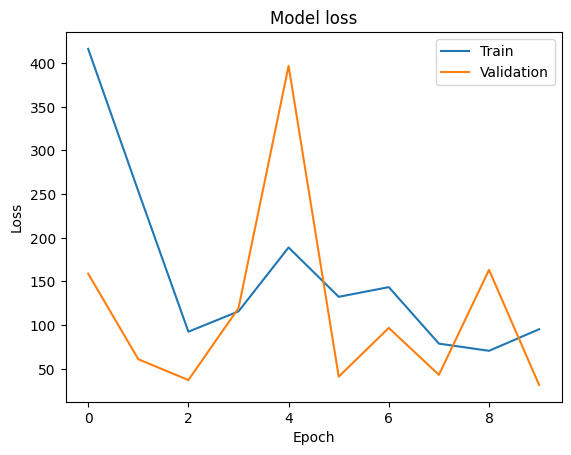

In [ ]:
# plot this loss graph
import matplotlib.pyplot as plt
plt.plot(model_1.history.history['loss'])
plt.plot(model_1.history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

In [ ]:
# 1. Open the original color image
color_image = Image.open(X_train[0])

# 2. Convert the image to grayscale ('L' mode)
grayscale_image = color_image.convert('L')

# 3. Save the converted image
grayscale_image.save('output_grayscale.jpg')


AttributeError: 'numpy.ndarray' object has no attribute 'read'